# Introduction

In this Quiz #1 you need to perform exploratory data analysis (EDA) and preprocessing using "Census Income" dataset. The dataset is tabular data which has several missing value in some variables. Moreover, you may need to adjust the name of variables (if needed).

To guide you through this task, some code has beed provided including, download the data, loading the data, and metadata inspection.

# Load Data and Inspect Metadata

In [ ]:
# Install UCI REPO Library
!pip install -q ucimlrepo

In [101]:
# Import Required Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

In [102]:
# fetch data
adult_income = fetch_ucirepo(id=2)

In [103]:
# Data
X = adult_income.data.features
y = adult_income.data.targets

# Concate Features and Target
df = pd.concat([X, y], axis=1)

# Show Top 5
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [104]:
# Data Size
df.shape

(48842, 15)

In [ ]:
# Inspect metadata
adult_income.metadata

# Part 1 - Data Loading dan Data Imputation

## Task 1 (5 points)
1.   Do inspection to get the information about dataset
2.   **Which variable(s)** has **missing values**? **How many is it**?



In [114]:
# Answer task 1 using this cell
# You can add another cell after this cell if needed

df.isnull().sum()

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


In [ ]:
# check any inapropriate / weirdness in all column
for col in df.columns:
  print(f"colum: {col} -> type: {df[col].dtype}")
  print(df[col].unique())
  print()

In [116]:
df.info()
df = df.replace('?', np.nan)
missing = df.isnull().sum()
missing = missing[missing > 0]
print(missing)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             48842 non-null  int64 
 1   workclass       48842 non-null  object
 2   fnlwgt          48842 non-null  int64 
 3   education       48842 non-null  object
 4   education-num   48842 non-null  int64 
 5   marital-status  48842 non-null  object
 6   occupation      48842 non-null  object
 7   relationship    48842 non-null  object
 8   race            48842 non-null  object
 9   sex             48842 non-null  object
 10  capital-gain    48842 non-null  int64 
 11  capital-loss    48842 non-null  int64 
 12  hours-per-week  48842 non-null  int64 
 13  native-country  48842 non-null  object
 14  income          48842 non-null  object
dtypes: int64(6), object(9)
memory usage: 5.6+ MB
Series([], dtype: int64)


## Task 2 (5 points)
1. Perform data imputation on missing values.
2. Verified the missing values for each variable. Is it still there?

In [117]:
# Answer task 2 using this cell
# You can add another cell after this cell if needed

df['workclass'] = df['workclass'].fillna(value=df['workclass'].mode()[0])
df['occupation'] = df['occupation'].fillna(value=df['occupation'].mode()[0])
df['native-country'] = df['native-country'].fillna(value="DARI BUMI")
df.isnull().sum()

# df[['workclass', 'occupation', 'native-country']]

,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0


## Task 3 (10 points)
Do inspection to all the quantitative variables (features). If you found an **inappropriate value(s)**, replace it with '**Others**'. Also, if you found any typos value(s), **fix the typos**.

In [118]:
# Answer task 3 using this cell
# You can add another cell after this cell if needed

cat_cols = df.select_dtypes(include="object").columns
for col in cat_cols:
  print(col ,"->" , df[col].unique())
  print()

workclass -> ['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' 'Local-gov'
 'Self-emp-inc' 'Without-pay' 'Never-worked']

education -> ['Bachelors' 'HS-grad' '11th' 'Masters' '9th' 'Some-college' 'Assoc-acdm'
 'Assoc-voc' '7th-8th' 'Doctorate' 'Prof-school' '5th-6th' '10th'
 '1st-4th' 'Preschool' '12th']

marital-status -> ['Never-married' 'Married-civ-spouse' 'Divorced' 'Married-spouse-absent'
 'Separated' 'Married-AF-spouse' 'Widowed']

occupation -> ['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' 'Protective-serv'
 'Armed-Forces' 'Priv-house-serv']

relationship -> ['Not-in-family' 'Husband' 'Wife' 'Own-child' 'Unmarried' 'Other-relative']

race -> ['White' 'Black' 'Asian-Pac-Islander' 'Amer-Indian-Eskimo' 'Other']

sex -> ['Male' 'Female']

native-country -> ['United-States' 'Cuba' 'Jamaica' 'India' 'DARI BUMI' 'Mexico' 'South'
 'Puerto-Rico'

In [119]:
df['income'] = df['income'].str.replace('.', '', regex=False).str.strip()
for col in cat_cols:
  counts = df[col].value_counts()
  rare = counts[counts < 50].index
  df[col] = df[col].replace(rare, "Others")

In [122]:
print(df['occupation'].unique())
print()
print(df['native-country'].unique())
print()
print(df['workclass'].unique())
print()

print('========')
print("the '?' & income -> <=50K, >50K,<=50K., >50K. is now gone")

['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' 'Protective-serv'
 'Others' 'Priv-house-serv']

['United-States' 'Cuba' 'Jamaica' 'India' 'DARI BUMI' 'Mexico' 'South'
 'Puerto-Rico' 'Others' 'England' 'Canada' 'Germany' 'Iran' 'Philippines'
 'Italy' 'Poland' 'Columbia' 'Taiwan' 'Haiti' 'Portugal'
 'Dominican-Republic' 'El-Salvador' 'Guatemala' 'China' 'Japan' 'Vietnam']

['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' 'Local-gov'
 'Self-emp-inc' 'Others']

the '?' & income -> <=50K, >50K,<=50K., >50K. is now gone


# Part 2 - Visual Inspection



## Task 1 - Data Visualization (20 points)
Do inspection on this following variabels,
1. On the 'age' by using a histogram
2. On the 'education' using a barchart
3. On the 'income' to 'hours_per_week' by using a boxplot (grouped by income)
4. On the 'age' to 'capital-gain' and 'capital-loss' using lineplot (lineplot with multiple x-data)

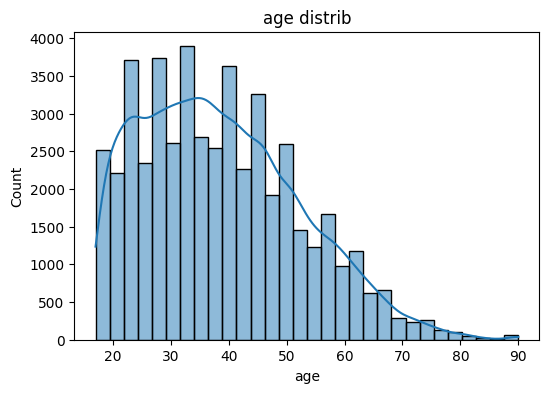

In [123]:
# Answer 1.1 - Histrogram

plt.figure(figsize=(6,4))
sns.histplot(df['age'], bins=30, kde=True)
plt.title("age distrib")
plt.show()

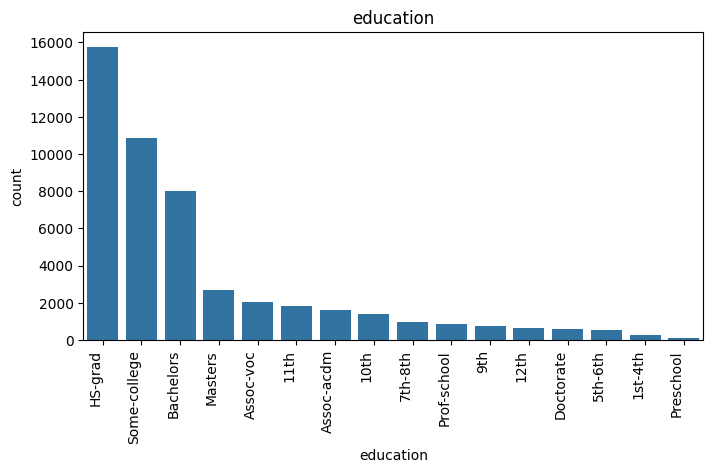

In [125]:
# Answer 1.2 - Barchart

plt.figure(figsize=(8,4))
order = df['education'].value_counts().index
sns.countplot(data=df, x='education', order=order)
plt.xticks(rotation=90, ha='right')
plt.title("education")
plt.show()

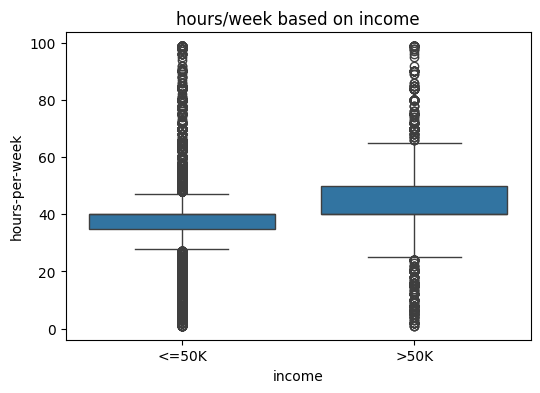

In [126]:
# Answer 1.3 - Boxplot

plt.figure(figsize=(6,4))
sns.boxplot(data=df, x='income', y='hours-per-week')
plt.title("hours/week based on income")
plt.show()

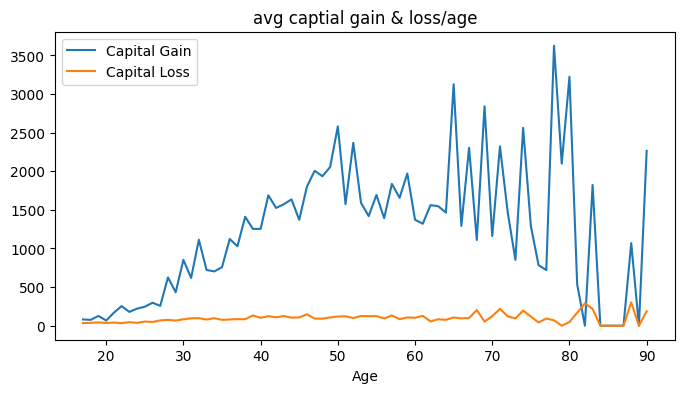

In [127]:
# Answer 1.4 - Lineplot

df_group = df.groupby('age')[['capital-gain','capital-loss']].mean().reset_index()
plt.figure(figsize=(8,4))
plt.plot(df_group['age'], df_group['capital-gain'], label='Capital Gain')
plt.plot(df_group['age'], df_group['capital-loss'], label='Capital Loss')
plt.xlabel("Age"); plt.legend()
plt.title("avg captial gain & loss/age")
plt.show()

## Task 2 - Visual Analysis (15 points)
1. What kind of distribution showed in 'age'?
2. If you find missing values in 'age', what kind of data impute method will you use? Why?
3. How many outliner for each category (group) in 'income' related to 'hour-per-week'? Which category has more outlier?

In [128]:
# Answer with python comment like this -> inline comment

'''
  1. right-skewed distribution (positively skewed)
  2. i would use MEDIAN IMPUTATION, fillna(value=df['age'].median()) because the age column distrib is skewed, & contain outlier on the upperend
  3. both categories contain numerous outlier due to narrow iqr centered around a standard 40 hours, but the <= 50k group has more outliers because it represents big majority of total sample
'''

"\n  1. right-skewed distribution (positively skewed)\n  2. i would use MEDIAN IMPUTATION, fillna(value=df['age'].median()) because the age column distrib is skewed, & contain outlier on the upperend\n  3. both categories contain numerous outlier due to narrow iqr centered around a standard 40 hours, but the <= 50k group has more outliers because it represents big majority of total sample\n"

# Part 3 - Encoding in Categorical Variable

## Task 1 (5 points)
Do encoding process on 'Sex' and 'Income', while 'Income' is target variable.

In [129]:
# Answer task 1 using this cell
# You can add another cell after this cell if needed

from sklearn.preprocessing import LabelEncoder

le_sex = LabelEncoder()
le_income = LabelEncoder()

df['sex_encoded'] = le_sex.fit_transform(df['sex'])
df['income_encoded'] = le_income.fit_transform(df['income'])

print(le_sex.classes_)
print(le_income.classes_)

['Female' 'Male']
['<=50K' '>50K']


# Part 4 - Correlation Analysis

## Task 1 (10 points)
1. Do correlation analysis on the following variabels: 'age', 'education-num', 'hours-per-week', 'capital-gain', 'capital-loss', and 'income' (encoded version from previous task)
2. Based on the result, what kind of information you get?

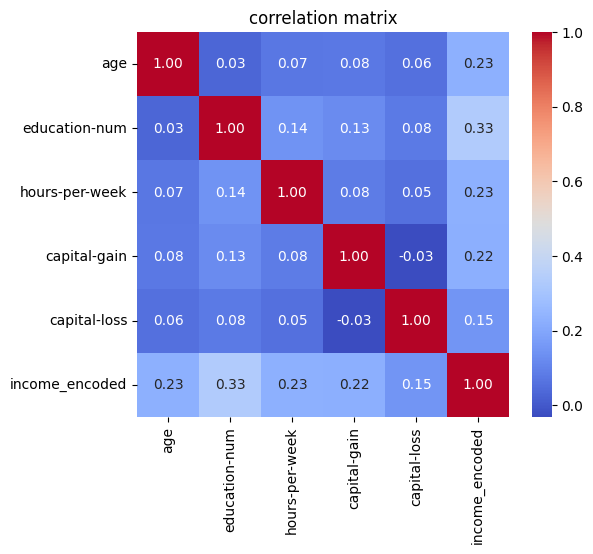

In [130]:
# Answer task 1 using this cell
# You can add another cell after this cell if needed

corr_cols = ['age', 'education-num', 'hours-per-week', 'capital-gain', 'capital-loss', 'income_encoded']
corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("correlation matrix")
plt.show()

In [131]:
# Answer task 2 using this cell -> you can use multiple comments style too
'''
  - education-num usually has the strongest positive correlation w/ income -> higher education to mean higher chance of >50K income
  - capital-gain also tends to correlate postiively with income
  - age and hours-per-week usually show weaker correlation
  - so higher education & capital-gain val mean ties to high income
  - age & hours/week not that matter

  this mean it gives an early hint of which features matter most, just like in jobsheet 03
'''

'\n  - education-num usually has the strongest positive correlation w/ income -> higher education to mean higher chance of >50K income\n  - capital-gain also tends to correlate postiively with income\n  - age and hours-per-week usually show weaker correlation\n  - so higher education & capital-gain val mean ties to high income\n  - age & hours/week not that matter\n  \n  this mean it gives an early hint of which features matter most, just like in jobsheet 03\n'

# Part 5 - Preprocessing on MNIST Dataset

In this part, you need to perform EDA and simple preprocessing on MNIST dataset. This dataset contain images of handwritten digit from 0 to 9. A pre configuration is provided to help you to load the data and inspect some images.

Hints:
1. You only need to use the **Test** set.
2. You need to perform to all of images in test set (10k images). You may need a function to complete this task (optional).

In [132]:
# Fetch data and inspect data shape
from tensorflow.keras.datasets import mnist
import numpy as np
import matplotlib.pyplot as plt

# Load train & test split
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)

Train shape: (60000, 28, 28)
Test shape: (10000, 28, 28)


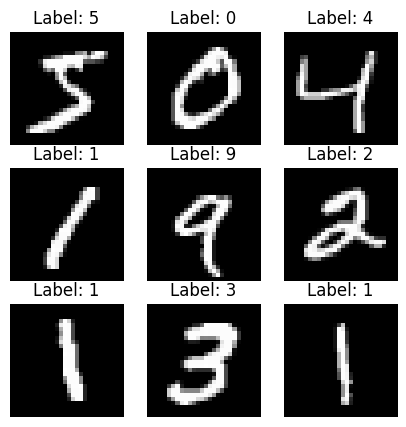

In [133]:
# Visual Inspection
plt.figure(figsize=(5,5))
for i in range(9):
    plt.subplot(3,3,i+1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")
plt.show()

## Task 1 (10 points)
1. Perform **upsampling** on the images to 32x32
2. Show the 5 sample of the result.


Hint: You need to store the result in an empty array. Replacing data to the  **X_test** cannot be done due to the shape of the array (10000, (28,28)). You need to create an array which match with the size of the new images.

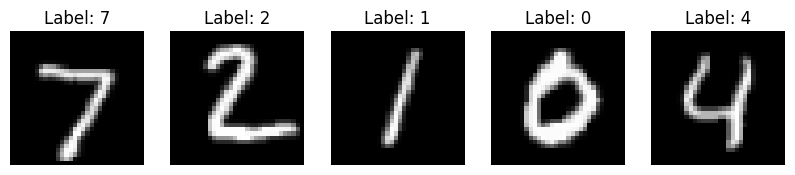

In [134]:
# Answer task 1 using this cell
# You can add another cell after this cell if needed
import cv2

X_test_resized = np.zeros((X_test.shape[0], 32, 32), dtype=np.uint8)
for i in range(X_test.shape[0]):
  X_test_resized[i] = cv2.resize(X_test[i], (32, 32), interpolation=cv2.INTER_LINEAR)

plt.figure(figsize=(10,2))
for i in range(5):
  plt.subplot(1,5,i+1)
  plt.imshow(X_test_resized[i], cmap='gray')
  plt.title(f"Label: {y_test[i]}")
  plt.axis('off')

plt.show()


## Task 2 (10 points)
Perform normalization, so the pixel value will have a value in range of 0 until 1

In [136]:
# Answer task 2 using this cell
# You can add another cell after this cell if needed
X_test_norm = X_test_resized.astype('float32') / 255

## Task 3 (10 points)
Transform / reshape the images into 1 dimensional array. Do it to the all images (after resizing and normalization).

Hint: You may need an empty array to store the result

In [137]:
# Answer task 3 using this cell
# You can add another cell after this cell if needed
X_test_flat = X_test_norm.reshape(X_test_norm.shape[0], -1)
print(X_test_flat.shape)

(10000, 1024)
